# 05 · Explainability with SHAP

**Goal:** show *why* the headline model (pre-transaction XGBoost) flags a
transaction, both overall and for individual cases, in terms a fraud analyst
could use.

- SHAP values come from `shap.TreeExplainer` on the saved model, cut to its best
  early-stopped iteration so the explanations match the model's actual scores.
- They are computed on a stratified sample of the **test** set. The model and
  threshold were frozen in notebooks 03 and 04; nothing here changes them.
- SHAP values are in **log-odds**: base value + the sum of a row's SHAP values
  gives the model's margin, and the fraud score is the sigmoid of that margin.
  Positive values push towards "fraud".

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from src.data import load_data
from src.features import filter_relevant, default_boundaries, time_split, build_features
from src.train import load_model
from src.explain import (FEATURE_LABELS, HEADLINE_NAME, shap_explanation, check_additivity,
                         sample_for_shap, explain_transaction)
from src.plotting import set_style, save_fig

SEED = 42
np.random.seed(SEED)
set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("shap version:", shap.__version__)

shap version: 0.53.0


## 1. Model, test set and a stratified sample

In [2]:
df = load_data(money_dtype="float64")
df = filter_relevant(df, verbose=False)
train_end, val_end = default_boundaries(df["step"])
_, _, test = time_split(df, train_end, val_end, verbose=False)
del df

model = load_model("xgb_pre_transaction")
threshold = json.loads((ROOT / "reports" / "final_metrics.json").read_text())[
    "thresholds_chosen_on_validation"][HEADLINE_NAME]

X_test = build_features(test, feature_set="pre_transaction")
y_test = test["isFraud"].astype(int)
test_scores = pd.Series(model.predict_proba(X_test)[:, 1], index=X_test.index)
test_pred = (test_scores >= threshold).astype(int)

idx = sample_for_shap(y_test, test_pred, n_fraud=500, n_legit=5000, seed=SEED)
X_s, y_s = X_test.loc[idx], y_test.loc[idx]
print(f"Threshold (chosen on validation): {threshold}")
print(f"Test set: {len(y_test):,} rows, {int(y_test.sum()):,} frauds, "
      f"{int(((test_pred == 1) & (y_test == 0)).sum())} false positives, "
      f"{int(((test_pred == 0) & (y_test == 1)).sum())} false negatives")
print(f"SHAP sample: {len(idx):,} rows ({int(y_s.sum())} frauds, {int((y_s == 0).sum()):,} legit; "
      "every misclassified row included)")

Threshold (chosen on validation): 0.394
Test set: 37,971 rows, 1,244 frauds, 0 false positives, 1 false negatives
SHAP sample: 5,500 rows (500 frauds, 5,000 legit; every misclassified row included)


In [3]:
explanation = shap_explanation(model, X_s)   # readable names and raw amounts for plots
gap = check_additivity(model, X_s, explanation)
print(f"Additivity check passed: base value + SHAP values reproduce the scores (max gap {gap:.1e})")
print(f"Base value (log-odds): {np.mean(explanation.base_values):.3f}")

mean_abs = pd.Series(np.abs(explanation.values).mean(axis=0), index=explanation.feature_names)
mean_abs.sort_values(ascending=False).to_frame("mean |SHAP| (log-odds)")

Additivity check passed: base value + SHAP values reproduce the scores (max gap 2.4e-07)
Base value (log-odds): -2.504


,mean |SHAP| (log-odds)
Amount / origin balance,0.8019
Destination balance was 0,0.1141
Hour of day,0.0743
Origin opening balance (log),0.0508
Destination opening balance (log),0.0430
Is TRANSFER (vs CASH_OUT),0.0350
Amount (log),0.0246


## 2. Global explanation

Which features drive the model's scores across the sample? Note that the sample
over-represents fraud (about 1 in 11 rows instead of 1 in 30), so mean |SHAP|
describes this mix rather than the raw test set.

C:\Users\DELL\AppData\Local\Temp\ipykernel_9028\802235853.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(explanation.values, X_display, show=False, max_display=10)


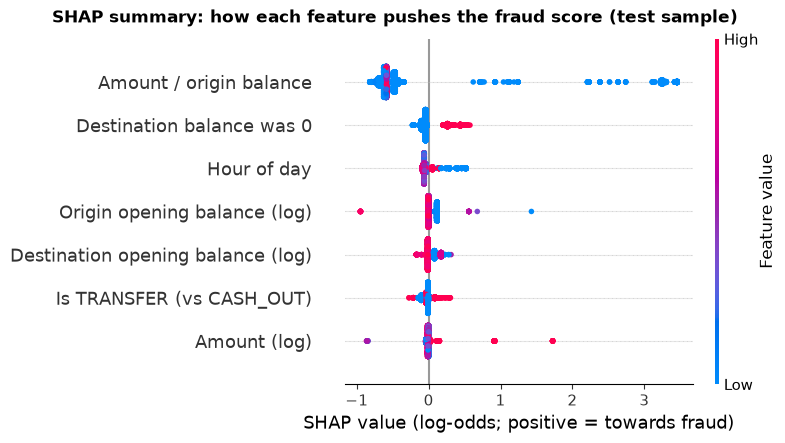

In [4]:
X_display = X_s.rename(columns=FEATURE_LABELS)
plt.figure()
shap.summary_plot(explanation.values, X_display, show=False, max_display=10)
fig = plt.gcf()
fig.suptitle("SHAP summary: how each feature pushes the fraud score (test sample)",
             fontweight="bold", y=1.02)
fig.axes[0].set_xlabel("SHAP value (log-odds; positive = towards fraud)")
save_fig(fig, "shap_beeswarm")
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_9028\4163328122.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(explanation.values, X_display, plot_type="bar", show=False, max_display=10)


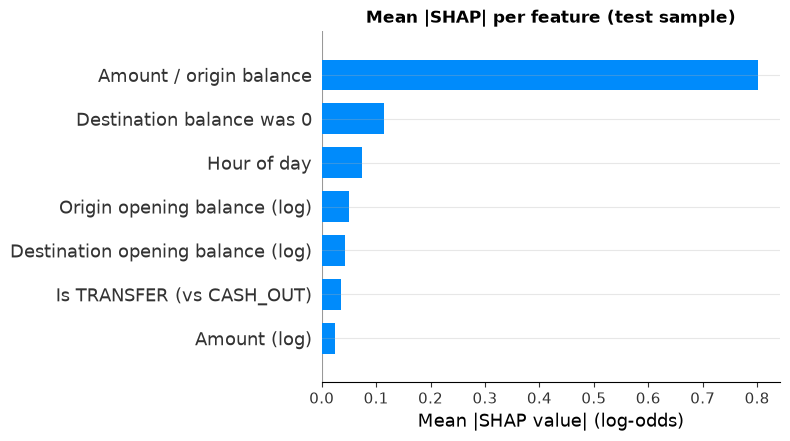

In [5]:
plt.figure()
shap.summary_plot(explanation.values, X_display, plot_type="bar", show=False, max_display=10)
fig = plt.gcf()
fig.axes[0].set_title("Mean |SHAP| per feature (test sample)", fontweight="bold")
fig.axes[0].set_xlabel("Mean |SHAP value| (log-odds)")
save_fig(fig, "shap_importance_bar")
plt.show()

**Interpretation**

- **One feature dominates.** `Amount / origin balance` has a mean |SHAP| of 0.80
  log-odds, about **7 times** the next feature (`Destination balance was 0`,
  0.11). Every other feature is below 0.08. This is the one-line rule from
  notebook 03 seen from inside the model.
- **Does the direction make sense? Yes, once the colours are read correctly.** The
  large pushes towards fraud (+2 to +3.5) are transactions whose amount equals the
  origin's **entire balance**: the pre-transaction version of "the origin account
  is emptied". They appear *blue* (low) only because the colour scale is stretched
  by legitimate transfers from empty accounts, where the ratio equals the amount
  itself (often hundreds of thousands). Next to those, a ratio of exactly 1 counts
  as "low". Those empty-origin transactions sit at about -0.6, so the model treats
  "no money in the account" as a sign of legitimacy. That is a PaySim quirk: 47%
  of legitimate transfers come from accounts already at zero.
- **The smaller effects are sensible too.** A destination with a zero prior
  balance raises the score (fraud often moves money into a fresh account: 65% of
  frauds vs 14% of legitimate transactions in the EDA). Early-morning hours raise
  it (a simulator artefact: legitimate activity stops at night). TRANSFER raises it
  slightly over CASH_OUT, and an amount of exactly 10,000,000 raises it strongly,
  which picks up the capped chunks used to drain large balances.
- **Overall:** the model behaves as expected for PaySim, but it leans almost
  entirely on one rule. A model validator would ask for this to be documented,
  since it will not hold on real data.

## 3. Local explanations: individual transactions

Three true positives, one false positive and one false negative, all at the
validation-chosen threshold. If the test set has no false positive, the
legitimate transaction with the **highest score** is used instead: the one that
came closest to being a false alarm.

In [6]:
rng = np.random.default_rng(SEED)
tp = y_s.index[(y_s == 1) & (test_pred.loc[idx] == 1)]
fp = y_s.index[(y_s == 0) & (test_pred.loc[idx] == 1)]
fn = y_s.index[(y_s == 1) & (test_pred.loc[idx] == 0)]
legit = y_s.index[y_s == 0]

cases = [(f"true positive {i + 1}", j) for i, j in enumerate(rng.choice(tp, 3, replace=False))]
if len(fp):
    cases.append(("false positive", fp[0]))
else:
    cases.append(("closest legit (no false positives)", test_scores.loc[legit].idxmax()))
if len(fn):
    cases.append(("false negative", fn[0]))

raw_cols = ["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig",
            "oldbalanceDest", "newbalanceDest", "isFraud"]
case_table = test.loc[[j for _, j in cases], raw_cols].assign(
    role=[r for r, _ in cases], score=[test_scores.loc[j] for _, j in cases]).set_index("role")
case_table

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,score
role,,,,,,,,,
true positive 1,702,TRANSFER,"10,000,000.0000","33,171,085.5900","23,171,085.5900",0.0000,0.0000,1,0.7833
true positive 2,642,CASH_OUT,"330,665.0200","330,665.0200",0.0000,"751,482.2300","1,082,147.2600",1,0.6939
true positive 3,718,CASH_OUT,"376,639.0500","376,639.0500",0.0000,0.0000,"376,639.0500",1,0.7764
closest legit (no false positives),695,TRANSFER,"70,207.1800","134,365.0000","64,157.8200",0.0000,"70,207.1800",0,0.1210
false negative,646,TRANSFER,"399,045.0800","10,399,045.0800","10,399,045.0800",0.0000,0.0000,1,0.0844


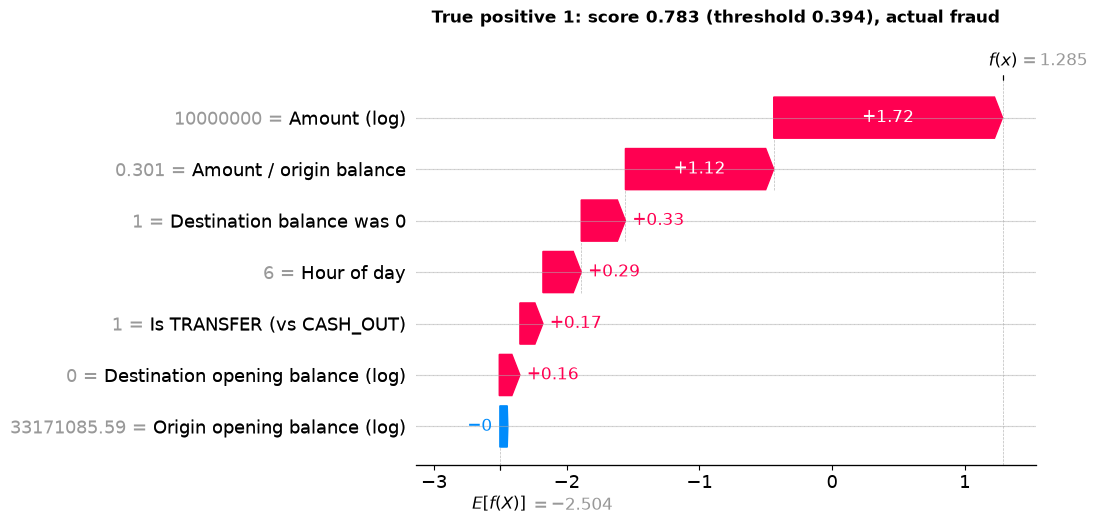

Flagged for review (score 0.783, threshold 0.394). The amount is exactly 10,000,000, the largest single transfer, which raises the fraud score.
  - The amount is exactly 10,000,000, the largest single transfer, which raises the fraud score. (SHAP +1.72)
  - The transfer is a 10,000,000 chunk of a 33,171,086 balance (large balances are drained in 10M chunks), which raises the fraud score. (SHAP +1.12)
  - The destination account had a zero prior balance (new or empty account), which raises the fraud score. (SHAP +0.33)



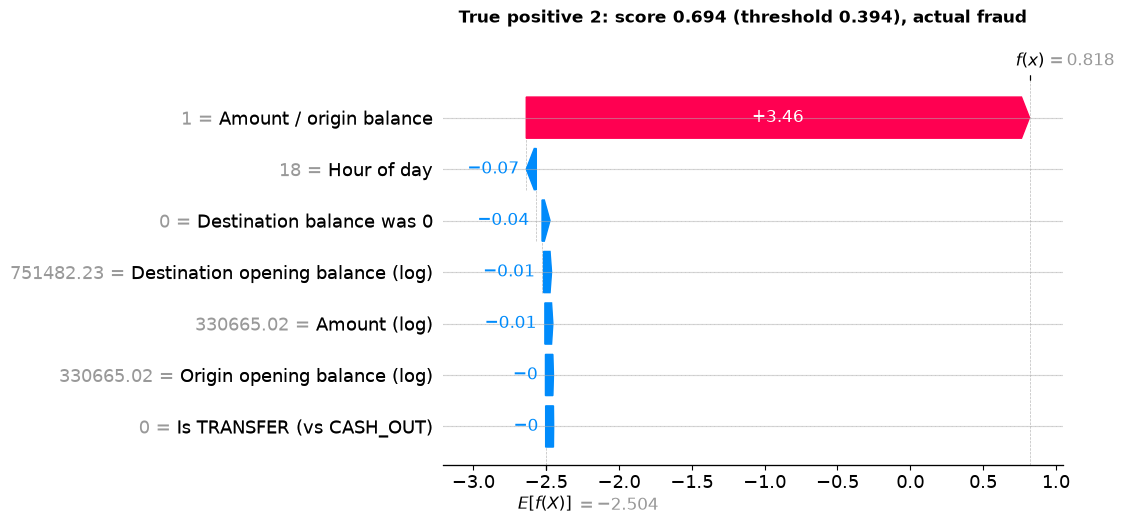

Flagged for review (score 0.694, threshold 0.394). The transfer moves the origin account's entire balance (330,665.02), which raises the fraud score.
  - The transfer moves the origin account's entire balance (330,665.02), which raises the fraud score. (SHAP +3.46)
  - It happened at hour 18, which lowers the fraud score. (SHAP -0.07)
  - The destination account already held funds, which lowers the fraud score. (SHAP -0.04)



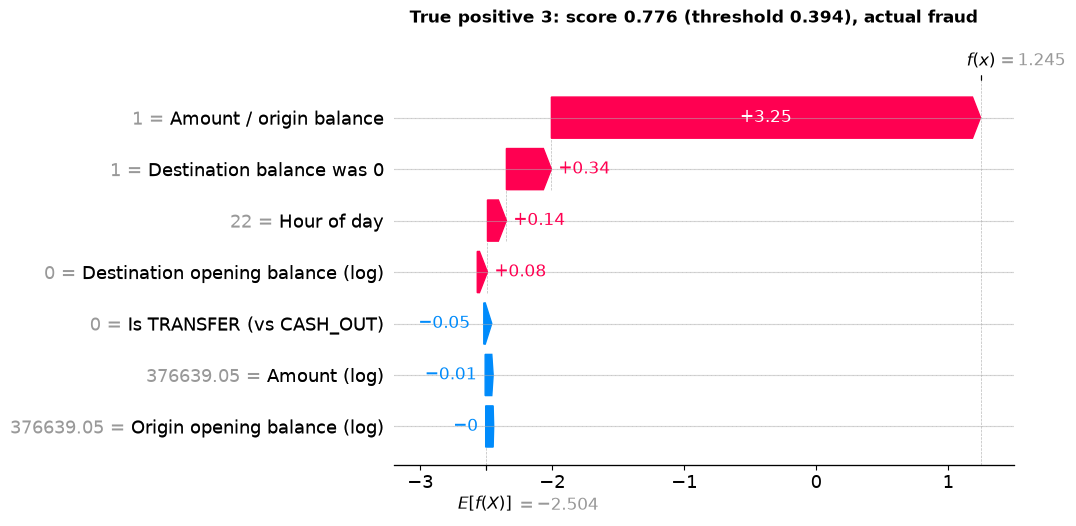

Flagged for review (score 0.776, threshold 0.394). The transfer moves the origin account's entire balance (376,639.05), which raises the fraud score.
  - The transfer moves the origin account's entire balance (376,639.05), which raises the fraud score. (SHAP +3.25)
  - The destination account had a zero prior balance (new or empty account), which raises the fraud score. (SHAP +0.34)
  - It happened at hour 22, which raises the fraud score. (SHAP +0.14)



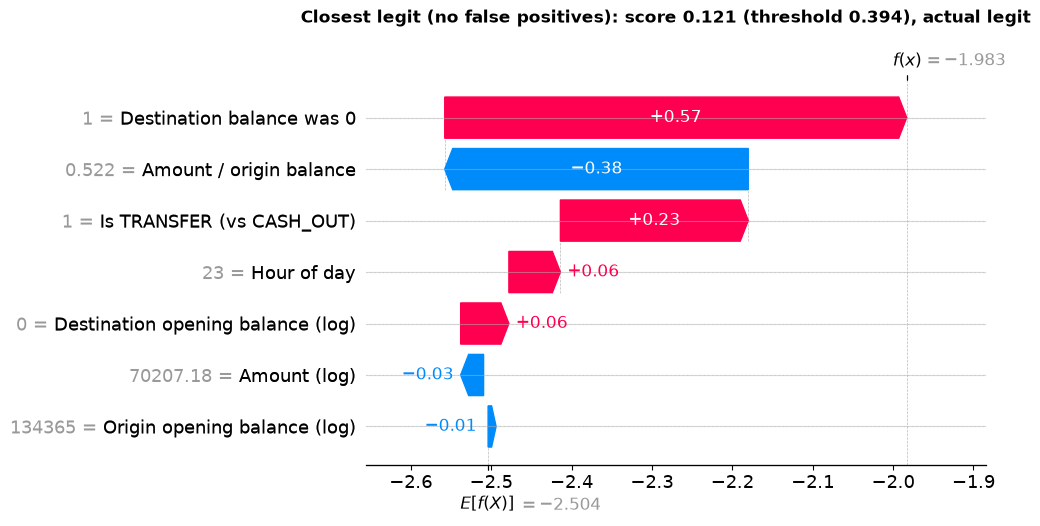

Not flagged (score 0.121, threshold 0.394). The destination account had a zero prior balance (new or empty account), which raises the fraud score.
  - The destination account had a zero prior balance (new or empty account), which raises the fraud score. (SHAP +0.57)
  - The transfer uses 52% of the origin balance, which lowers the fraud score. (SHAP -0.38)
  - It is a TRANSFER, which raises the fraud score. (SHAP +0.23)



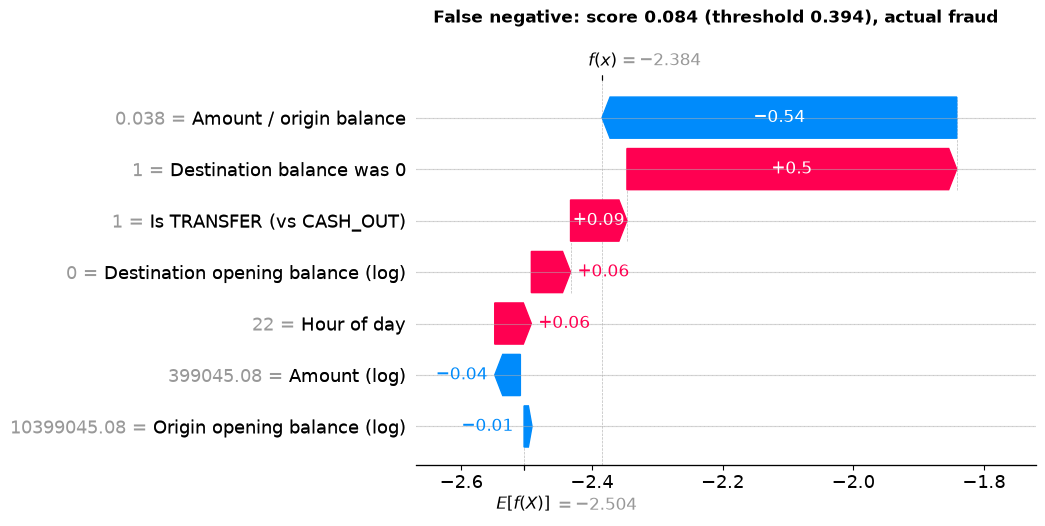

Not flagged (score 0.084, threshold 0.394). The transfer uses 4% of the origin balance, which lowers the fraud score.
  - The transfer uses 4% of the origin balance, which lowers the fraud score. (SHAP -0.54)
  - The destination account had a zero prior balance (new or empty account), which raises the fraud score. (SHAP +0.50)
  - It is a TRANSFER, which raises the fraud score. (SHAP +0.09)



In [7]:
position = {label: i for i, label in enumerate(idx)}
for role, j in cases:
    plt.figure()
    shap.plots.waterfall(explanation[position[j]], max_display=8, show=False)
    fig = plt.gcf()
    fig.suptitle(f"{role.capitalize()}: score {test_scores.loc[j]:.3f} "
                 f"(threshold {threshold}), actual {'fraud' if y_test.loc[j] else 'legit'}",
                 fontweight="bold", y=1.02)
    save_fig(fig, "shap_waterfall_" + role.split(" (")[0].replace(" ", "_"))
    plt.show()

    result = explain_transaction(test.loc[j], model=model, threshold=threshold)
    print(result["summary"])
    for f in result["top_features"]:
        print(f"  - {f['text']} (SHAP {f['shap']:+.2f})")
    print()

**Analyst notes**

- **True positive 1 (score 0.783).** Flagged because this TRANSFER is exactly
  10,000,000, the largest single transfer, out of an account holding 33.2M, and it
  goes to a destination with a zero prior balance at 06:00. This matches an
  account being drained in 10M chunks; expect further transfers from the same
  account.
- **True positive 2 (score 0.694).** Flagged because the cash-out moves the origin
  account's entire balance of 330,665. Nothing else is unusual (the destination
  already held funds and 18:00 is a normal time), so the full-balance withdrawal
  alone carries the alert.
- **True positive 3 (score 0.776).** Flagged because the cash-out empties the
  account (the full 376,639) into a destination with no prior balance, late in the
  evening. Both are classic signs of funds being moved out through a fresh account.
- **Closest legitimate transaction (score 0.121; the test set has no false
  positives).** Not flagged: a TRANSFER of 70,207, about half (52%) of the origin
  balance, to an account with a zero prior balance. The empty destination and the
  TRANSFER type pushed the score up, but because the customer kept half the money
  it stayed far below the 0.394 threshold. Even the most suspicious-looking
  legitimate transaction is nowhere near an alert.
- **False negative (score 0.084): the one missed fraud.** Missed because, on its
  own, this TRANSFER of 399,045 uses only 4% of a 10.4M balance, which the model
  reads as normal. But 10,399,045 - 399,045 is exactly 10,000,000: this looks like
  the leftover piece of a balance being drained in 10M chunks. The model scores
  each transaction in isolation (the one-line rule misses it too). A feature that
  tracks recent transfers from the same account, such as the amount moved out in
  the last hour, would catch it.

## 4. `explain_transaction()` for the demo app

`src.explain.explain_transaction(row)` takes one raw transaction and returns the
score, the decision at the validation-chosen threshold and the top three
contributing features in plain English. It is what the Streamlit demo will call.

In [8]:
example = test.loc[cases[0][1], ["step", "type", "amount", "oldbalanceOrg", "oldbalanceDest"]].to_dict()
print("Input:", example)
explain_transaction(example)

Input: {'step': 702, 'type': 'TRANSFER', 'amount': 10000000.0, 'oldbalanceOrg': 33171085.59, 'oldbalanceDest': 0.0}


{'score': 0.7832561731338501,
 'flagged': True,
 'threshold': 0.394,
 'top_features': [{'feature': 'amount_log',
   'label': 'Amount (log)',
   'shap': 1.7243990898132324,
   'text': 'The amount is exactly 10,000,000, the largest single transfer, which raises the fraud score.'},
  {'feature': 'amount_to_balance_ratio',
   'label': 'Amount / origin balance',
   'shap': 1.1178898811340332,
   'text': 'The transfer is a 10,000,000 chunk of a 33,171,086 balance (large balances are drained in 10M chunks), which raises the fraud score.'},
  {'feature': 'dest_new_or_zero',
   'label': 'Destination balance was 0',
   'shap': 0.333019882440567,
   'text': 'The destination account had a zero prior balance (new or empty account), which raises the fraud score.'}],
 'summary': 'Flagged for review (score 0.783, threshold 0.394). The amount is exactly 10,000,000, the largest single transfer, which raises the fraud score.'}

## Why explainability matters in banking

A fraud model in a bank is not just a scoring engine; it has to be defended.
**Model governance** teams and validators need to see what drives the model
before approving it, and to notice when it leans on something it should not (here,
a simulator artefact). **Fraud analysts** reviewing an alert work faster and make
fewer mistakes when they are told why it fired. When a **customer disputes** a
blocked payment, staff need a reason they can give in plain language. And
**regulators** increasingly expect automated decisions that affect customers to be
explainable, documented and free of unjustified bias. SHAP gives each of these
audiences the same per-transaction breakdown, in terms of the inputs they already
understand.